# Exploration (02_EDA)

### Imports

In [6]:
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.insert(0, os.path.join("..", "src"))
from utils import LIBELLES_NAF, categoriser_juridique

sns.set_theme(style="whitegrid")

## Chargement des données

In [7]:
df = pd.read_parquet("../Data/processed/dataset_final.parquet")
df.shape

(16884648, 10)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16884648 entries, 0 to 16884647
Data columns (total 10 columns):
 #   Column                         Dtype         
---  ------                         -----         
 0   siren                          str           
 1   dateCreationUniteLegale        datetime64[ms]
 2   activitePrincipaleUniteLegale  str           
 3   categorieJuridiqueUniteLegale  int64         
 4   trancheEffectifsUniteLegale    str           
 5   categorieEntreprise            str           
 6   date_jugement                  datetime64[us]
 7   nature_jugement                str           
 8   defaillance                    bool          
 9   age_entreprise                 float64       
dtypes: bool(1), datetime64[ms](1), datetime64[us](1), float64(1), int64(1), str(5)
memory usage: 1.5 GB


## Feature `age_entreprise`

In [9]:
df["age_entreprise"].describe().round(2)

count    16884648.00
mean           16.05
std            16.92
min             0.00
25%             4.08
50%            11.16
75%            23.50
max           166.02
Name: age_entreprise, dtype: float64

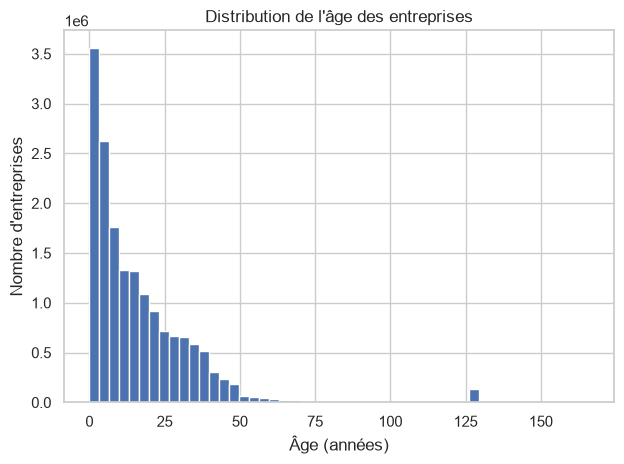

In [10]:
fig, ax = plt.subplots()

ax.hist(df["age_entreprise"], bins=50)

ax.set_title("Distribution de l'âge des entreprises")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre d'entreprises")

plt.tight_layout()
plt.show()

L'âge est très étalé vers la droite. La plupart des entreprises sont jeunes, mais quelques-unes sont très anciennes, ce qui tire la moyenne au-dessus de la médiane. On regardera plutôt la médiane pour cette variable.

In [11]:
df.groupby("defaillance")["age_entreprise"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
defaillance,,,,,,,,
False,16434984.0,16.17,17.03,0.00,4.08,11.33,23.72,166.02
True,449664.0,11.30,11.24,0.02,4.18,7.61,14.56,126.57


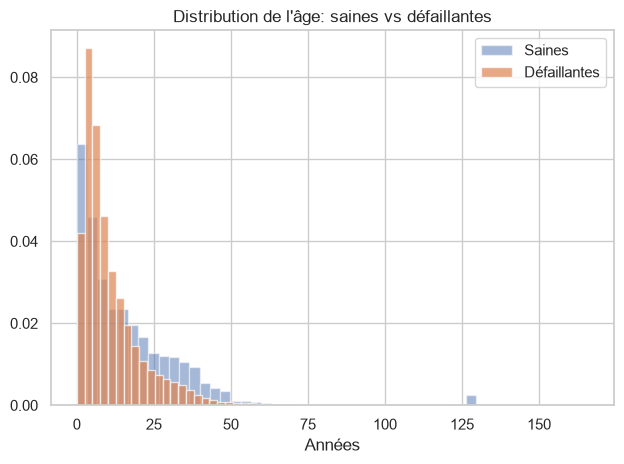

In [12]:
fig, ax = plt.subplots()

ax.hist(df[df["defaillance"] == False]["age_entreprise"], bins=50, alpha=0.5, label="Saines", density=True)
ax.hist(df[df["defaillance"] == True]["age_entreprise"], bins=50, alpha=0.7, label="Défaillantes", density=True)

ax.set_title("Distribution de l'âge: saines vs défaillantes")
ax.set_xlabel("Années")
ax.legend()

plt.tight_layout()
plt.show()

Comme l'âge est maintenant calculé à la date du jugement, les défaillantes ressortent nettement plus jeunes que les entreprises saines : médiane d'environ 7,6 ans contre 11,3. Les entreprises font donc souvent défaut assez tôt dans leur vie. L'âge devient un signal plus utile qu'avant la correction.

### Taux de défaillance par tranche d'âge 

In [13]:
# tranches un peu arbitraires, calquées sur les cycles de vie classiques
df["tranche_age"] = pd.cut(
    df["age_entreprise"],
    bins=[0, 2, 5, 10, 20, 30, 50, 200],
    labels=["0-2 ans", "2-5 ans", "5-10 ans", "10-20 ans", "20-30 ans", "30-50 ans", "50+ ans"]
)

taux_par_tranche = df.groupby("tranche_age")["defaillance"].mean() * 100
taux_par_tranche.round(2)

tranche_age
0-2 ans      1.28
2-5 ans      4.26
5-10 ans     4.40
10-20 ans    2.85
20-30 ans    1.67
30-50 ans    1.03
50+ ans      1.17
Name: defaillance, dtype: float64

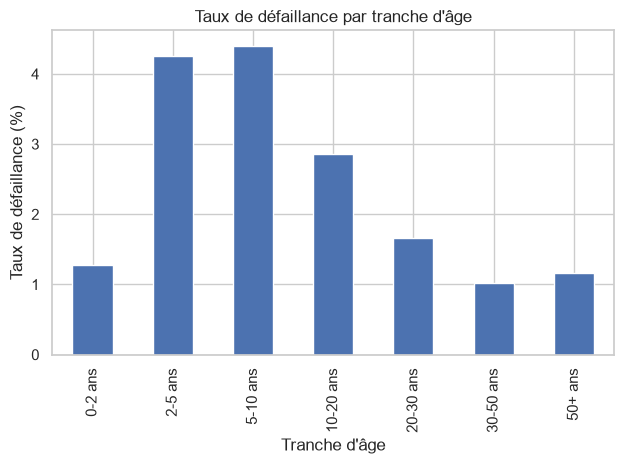

In [14]:
fig, ax = plt.subplots()

taux_par_tranche.plot.bar(ax=ax)

ax.set_title("Taux de défaillance par tranche d'âge")
ax.set_xlabel("Tranche d'âge")
ax.set_ylabel("Taux de défaillance (%)")

plt.tight_layout()
plt.show()

Le taux de défaillance ne monte pas de façon régulière avec l'âge : il est plus faible pour les toutes jeunes entreprises, atteint son maximum entre 2 et 10 ans (autour de 4,3-4,4 %), puis redescend pour les plus anciennes. La période la plus risquée est donc située peu après le démarrage. Cette relation non linéaire est une bonne raison d'utiliser plus loin des modèles à base d'arbres.

## Features catégorielles

### Secteur d'activité (code NAF)

In [15]:
# Extraire les 2 premiers caractères = division NAF
df["section_naf"] = df["activitePrincipaleUniteLegale"].str[:2]
df["libelle_naf"] = df["section_naf"].map(LIBELLES_NAF).fillna("Autre")

In [16]:
taux_naf = df.groupby("libelle_naf")["defaillance"].mean().sort_values(ascending=False) * 100
taux_naf.round(2)

libelle_naf
Dépollution                  16.40
Alimentation                 12.34
Restauration                 12.16
Sécurité                     10.53
Télécoms                      9.67
                             ...  
Administration publique       0.03
Organismes internationaux     0.00
Ménages producteurs           0.00
Ménages employeurs            0.00
Pétrole/gaz                   0.00
Name: defaillance, Length: 89, dtype: float64

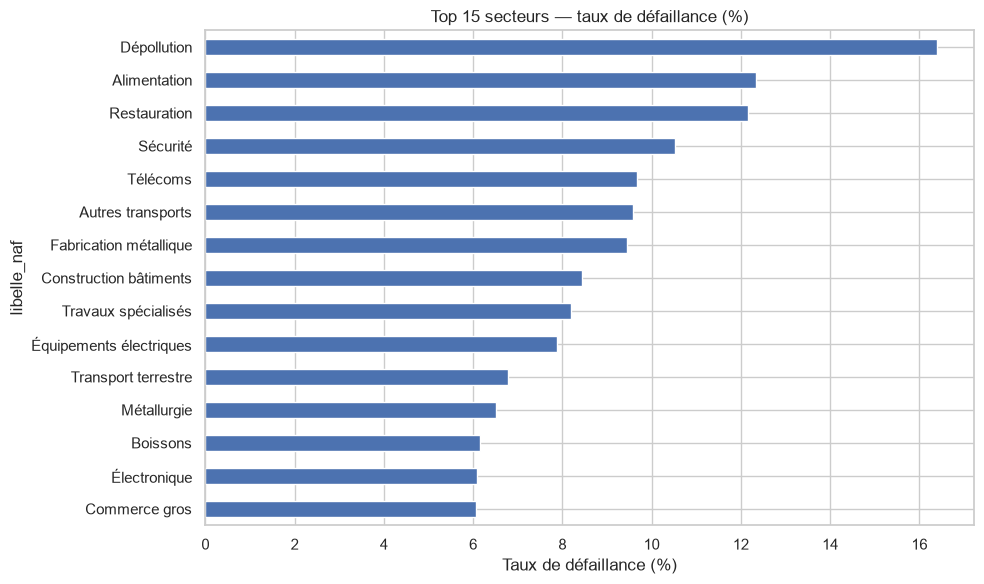

In [17]:
top15 = taux_naf.head(15)

fig, ax = plt.subplots(figsize=(10, 6))

top15[::-1].plot.barh(ax=ax)

ax.set_title("Top 15 secteurs — taux de défaillance (%)")
ax.set_xlabel("Taux de défaillance (%)")

plt.tight_layout()
plt.show()

L'écart entre secteurs est énorme (de presque 0 % à plus de 16 %). Les plus touchés sont la dépollution, l'alimentation, la restauration et la sécurité, des activités à faibles marges et très concurrentielles. À l'inverse, l'administration publique et les organismes internationaux ne font quasiment jamais défaut. Le secteur est donc une variable importante à garder.

### Forme juridique

In [18]:
df["forme_juridique"] = df["categorieJuridiqueUniteLegale"].apply(categoriser_juridique)

In [19]:
taux_juridique = df.groupby("forme_juridique")["defaillance"].mean().sort_values(ascending=False) * 100
taux_juridique.round(2)

forme_juridique
SA                         10.84
SAS                         8.87
SARL                        8.57
Autre                       0.94
Entrepreneur individuel     0.65
Société civile              0.56
Association                 0.37
Syndicat/GIE                0.01
Name: defaillance, dtype: float64

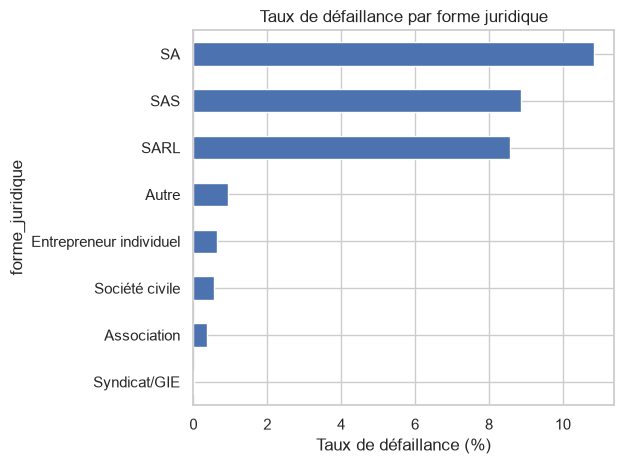

In [20]:

fig, ax = plt.subplots()

taux_juridique[::-1].plot.barh(ax=ax)

ax.set_title("Taux de défaillance par forme juridique")
ax.set_xlabel("Taux de défaillance (%)")

plt.tight_layout()
plt.show()

Les sociétés commerciales sont les plus exposées : SA (10,8 %), SAS (8,9 %), SARL (8,6 %). Les entrepreneurs individuels, sociétés civiles et associations sont très en dessous (moins de 1 %). C'est logique : les procédures collectives concernent surtout les sociétés, et ces formes portent plus de risque économique.

### Catégorie d'entreprise (PME / ETI / GE)

La colonne a 51 % de valeurs manquantes. On ne les supprime pas (ce serait la moitié des données), on les met dans une catégorie à part "Non renseigné". C'est d'ailleurs intéressant : les entreprises sans catégorie renseignée ont un taux de défaillance intermédiaire, donc l'absence d'information est elle-même un petit signal.

In [21]:
df["categorieEntreprise"] = df["categorieEntreprise"].fillna("Non renseigné")

taux_categorie = df.groupby("categorieEntreprise")["defaillance"].mean().sort_values(ascending=False) * 100
taux_categorie.round(2)

categorieEntreprise
PME              4.17
ETI              2.81
Non renseigné    1.25
GE               0.61
Name: defaillance, dtype: float64

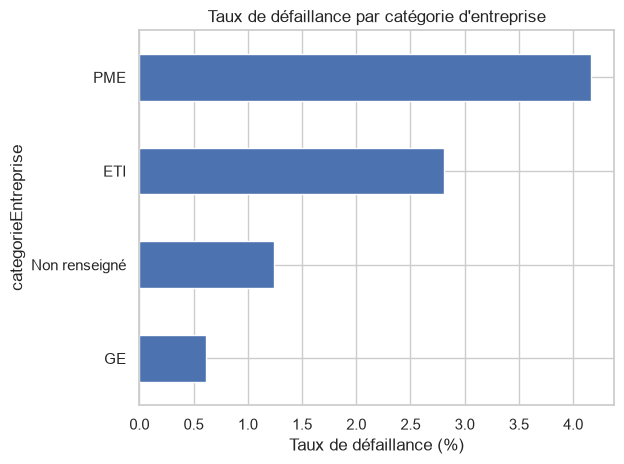

In [22]:
fig, ax = plt.subplots()

taux_categorie[::-1].plot.barh(ax=ax)

ax.set_title("Taux de défaillance par catégorie d'entreprise")
ax.set_xlabel("Taux de défaillance (%)")

plt.tight_layout()
plt.show()

Plus l'entreprise est grande, moins elle fait défaut : 4,2 % pour les PME, 2,8 % pour les ETI et 0,6 % pour les grandes entreprises. Les grandes structures sont plus solides et résistent mieux.

## Analyse temporelle

In [23]:
defaillants = df[df["defaillance"]].copy()
defaillants["annee"] = defaillants["date_jugement"].dt.year

annee
2019     4303
2020    98567
2021    54195
2022    52450
2023    61488
2024    68060
2025    68158
2026    42443
Name: count, dtype: int64


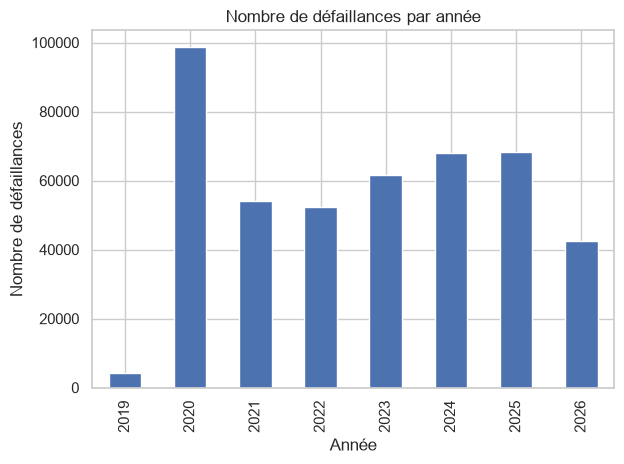

In [24]:
par_annee = defaillants["annee"].value_counts().sort_index()
print(par_annee)

fig, ax = plt.subplots()
par_annee.plot.bar(ax=ax)
ax.set_title("Nombre de défaillances par année")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de défaillances")
plt.tight_layout()
plt.show()

On regarde comment les défaillances se répartissent dans le temps. Les volumes sont faibles en 2019 et en 2026, et beaucoup plus élevés entre 2020 et 2025. Attention : le creux de 2019 et de 2026 ne veut pas dire qu'il y a eu moins de faillites. 2019 est le début de la période couverte par les données et 2026 n'est pas une année complète. C'est un effet de la fenêtre d'observation, pas un vrai signal.

## Interactions entre variables

### Âge moyen des défaillantes par secteur

In [25]:
age_par_secteur = df[df["defaillance"]].groupby("libelle_naf")["age_entreprise"].agg(["mean", "count"])
age_par_secteur = age_par_secteur[age_par_secteur["count"] >= 100].sort_values("mean")
age_par_secteur["mean"] = age_par_secteur["mean"].round(1)
age_par_secteur

,mean,count
libelle_naf,,
Restauration,8.3,56213
Livraison,8.3,724
Autre,8.5,790
Informatique,9.0,6654
Télécoms,9.2,916
...,...,...
Jeux de hasard,24.3,123
Hébergement médico-social,25.4,225
Audiovisuel,26.0,198


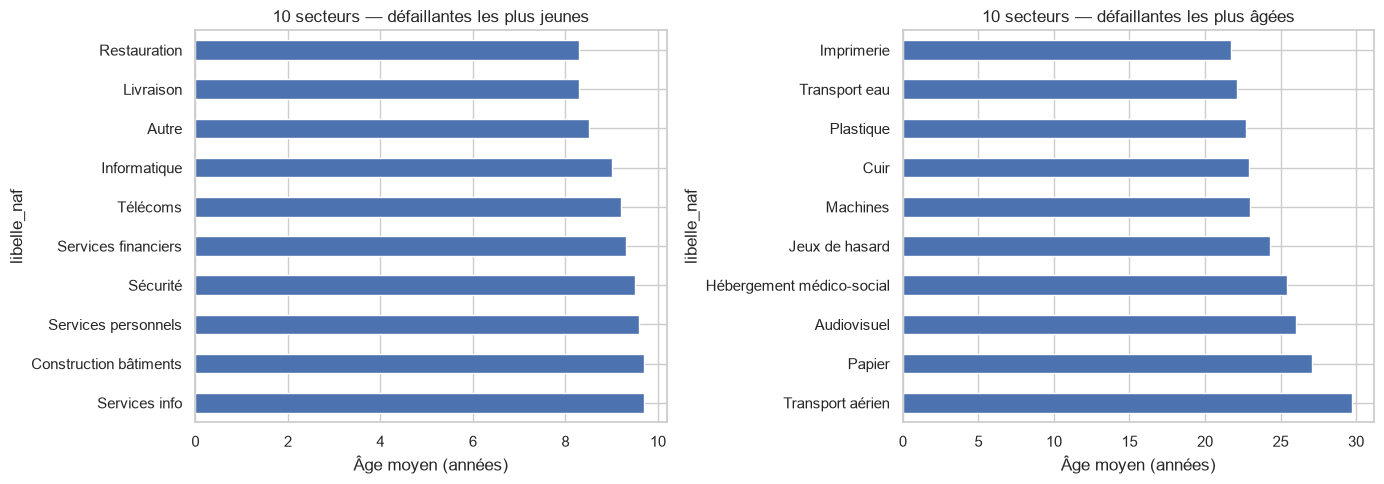

In [26]:
top10_jeunes = age_par_secteur.head(10)
top10_vieux = age_par_secteur.tail(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

top10_jeunes["mean"][::-1].plot.barh(ax=ax1)
ax1.set_title("10 secteurs — défaillantes les plus jeunes")
ax1.set_xlabel("Âge moyen (années)")

top10_vieux["mean"][::-1].plot.barh(ax=ax2)
ax2.set_title("10 secteurs — défaillantes les plus âgées")
ax2.set_xlabel("Âge moyen (années)")

plt.tight_layout()
plt.show()

L'âge auquel les entreprises tombent dépend beaucoup du secteur. Elles font défaut jeunes dans la livraison, la restauration ou l'informatique, des secteurs faciles à lancer mais où un modèle qui ne marche pas se voit vite. Elles font défaut bien plus tard dans le transport aérien, le papier ou l'audiovisuel, des secteurs lourds et établis qui déclinent lentement.

### Forme juridique × Secteur

In [27]:
croise = df.groupby(["forme_juridique", "libelle_naf"])["defaillance"].agg(["mean", "count"]).reset_index()
croise = croise[croise["count"] >= 200].sort_values("mean", ascending=False)
croise["mean"] = (croise["mean"] * 100).round(2)
croise.head()

,forme_juridique,libelle_naf,mean,count
346,SARL,Dépollution,26.32,323
480,SAS,Sécurité,19.07,9270
420,SAS,Autres transports,17.56,1088
479,SAS,Sylviculture,17.03,2489
487,SAS,Travaux spécialisés,16.92,179103


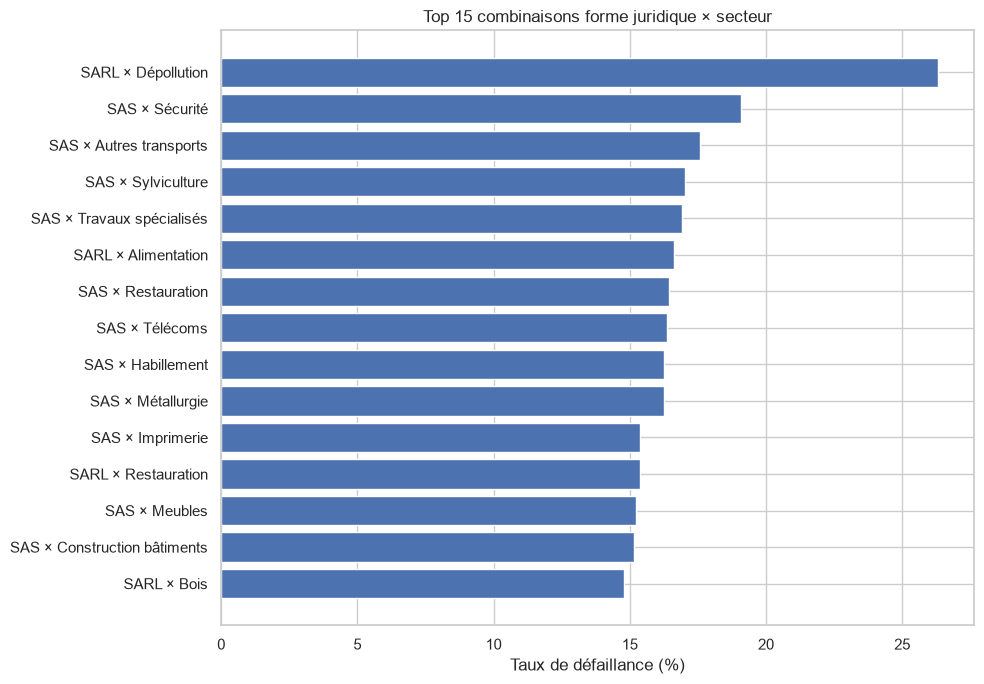

In [28]:
top15 = croise.head(15).copy()
top15["label"] = top15["forme_juridique"] + " × " + top15["libelle_naf"]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(top15["label"][::-1], top15["mean"][::-1])

ax.set_title("Top 15 combinaisons forme juridique × secteur")
ax.set_xlabel("Taux de défaillance (%)")

plt.tight_layout()
plt.show()

Les combinaisons forme juridique + secteur les plus risquées cumulent les deux effets, par exemple SARL en dépollution ou SAS en sécurité. Certains taux très hauts reposent sur peu d'entreprises et sont donc peu fiables : c'est pour ça qu'on a gardé seulement les combinaisons avec au moins 200 entreprises. Parmi celles à la fois risquées et fréquentes, on retrouve SAS en travaux spécialisés et SARL en restauration.

### Catégorie d'entreprise × Âge

In [29]:
age_par_categorie = df[df["defaillance"]].groupby("categorieEntreprise")["age_entreprise"].agg(["mean", "median", "count"])
age_par_categorie = age_par_categorie.sort_values("mean").round(1)
age_par_categorie

,mean,median,count
categorieEntreprise,,,
PME,10.7,7.2,339599
Non renseigné,13.0,9.1,107144
ETI,16.9,11.0,2690
GE,22.5,17.2,231


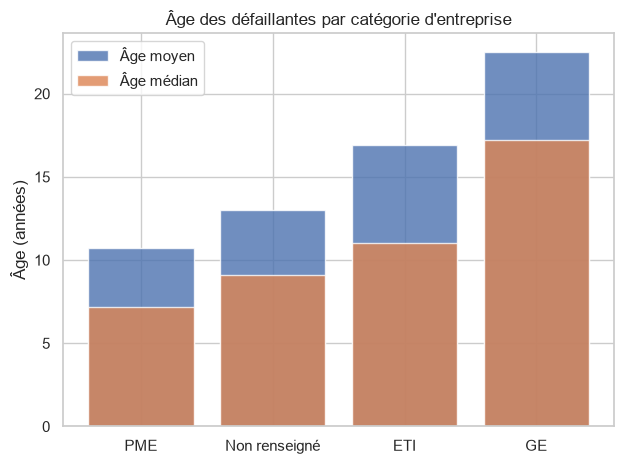

In [30]:
fig, ax = plt.subplots()

categories = age_par_categorie.index
x = range(len(categories))

ax.bar(x, age_par_categorie["mean"], label="Âge moyen", alpha=0.8)
ax.bar(x, age_par_categorie["median"], label="Âge médian", alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_title("Âge des défaillantes par catégorie d'entreprise")
ax.set_ylabel("Âge (années)")
ax.legend()

plt.tight_layout()
plt.show()

Plus l'entreprise est grande, plus elle fait défaut tard : l'âge médian au moment de la défaillance augmente de la PME vers la grande entreprise. Les grandes mettent plus de temps à se constituer et à sombrer, alors qu'une PME peut échouer jeune.

### Ce qu'on retient des données

Ce qui ressort de l'analyse :
- l'âge compte, avec un risque maximal pour les entreprises jeunes à d'âge moyen
- le secteur est très discriminant
- la forme juridique aussi : les sociétés commerciales font bien plus défaut que les entrepreneurs individuels
- la taille joue : les PME sont plus exposées que les grandes entreprises
- il existe des effets de combinaison entre secteur et forme juridique

Limite principale à garder en tête : la cible est très déséquilibrée (2,7 % de défaillances).

### Choix pour la modélisation

Pour la modélisation :
- Variables gardées : âge, secteur (code NAF), forme juridique, catégorie d'entreprise, un indicateur disant si l'effectif est renseigné, et l'interaction forme × secteur.
- Variables écartées : le siren (identifiant), la dénomination (texte), et surtout la date et la nature du jugement, qui sont postérieures à la défaillance. Les utiliser reviendrait à tricher.
- Déséquilibre : géré avec les poids de classe (class_weight / scale_pos_weight) plutôt qu'en ré-échantillonnant.
- Validation : séparation train/test stratifiée 80/20. Une validation dans le temps serait une amélioration possible.